In [1]:
# Configuración de GPU
import os
import gc
import time
import random
import platform
import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = "cuda"
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU total:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    DEVICE = "cpu"
    print("GPU no disponible. Se utilizará CPU.")

print("Dispositivo:", DEVICE)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)

GPU no disponible. Se utilizará CPU.
Dispositivo: cpu
Python: 3.13.16
PyTorch: 2.11.0+cpu


In [2]:
# Instalación de dependencias
%pip install -q -U transformers accelerate datasets evaluate scikit-learn huggingface_hub safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 92.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 17.4 MB/s eta 0:00:00


In [3]:
# Autenticación de Hugging Face
from huggingface_hub import login
from google.colab import userdata

try:
    HF_TOKEN = userdata.get("HF_TOKEN")
    if HF_TOKEN:
        login(token=HF_TOKEN, add_to_git_credential=False)
        print("Autenticación en Hugging Face completada.")
    else:
        print("Sin token: se utilizará acceso público.")
except Exception:
    print("No se encontró un secreto HF_TOKEN.")
    print("Se continuará con los modelos públicos.")

No se encontró un secreto HF_TOKEN.
Se continuará con los modelos públicos.


In [4]:
# Definición de los modelo
MODELS = {
    "DistilBART MNLI":
        "valhalla/distilbart-mnli-12-1",

    "BART Large MNLI":
        "facebook/bart-large-mnli",

    "BGE-M3 Zero-Shot":
        "MoritzLaurer/bge-m3-zeroshot-v2.0-c"
}

for name, model_id in MODELS.items():
    print(f"{name}: {model_id}")

DistilBART MNLI: valhalla/distilbart-mnli-12-1
BART Large MNLI: facebook/bart-large-mnli
BGE-M3 Zero-Shot: MoritzLaurer/bge-m3-zeroshot-v2.0-c


In [1]:
# Solución a la incompatibilidad de pyarrow
%pip install -q -U pyarrow

# Creación del dataset de skincare
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
import pandas as pd

LABELS = [
    "skin_profile",
    "cosmetic_goal",
    "ingredient_avoidance",
    "budget",
    "product_preference",
    "product_recommendation"
]

examples = [
    ("Tengo piel grasa y busco una crema hidratante",
     ["skin_profile", "cosmetic_goal", "product_recommendation"]),

    ("Quiero un limpiador para piel sensible",
     ["skin_profile", "product_recommendation"]),

    ("Busco un hidratante sin fragancia",
     ["ingredient_avoidance", "product_recommendation"]),

    ("No quiero productos con perfume",
     ["ingredient_avoidance"]),

    ("Mi presupuesto máximo es de 400 pesos",
     ["budget"]),

    ("Quiero una crema ligera para piel mixta",
     ["skin_profile", "product_preference", "product_recommendation"]),

    ("Necesito algo para hidratar la piel seca",
     ["skin_profile", "cosmetic_goal", "product_recommendation"]),

    ("Busco un gel facial que no deje sensación grasosa",
     ["product_preference", "product_recommendation"]),

    ("Tengo piel sensible y quiero evitar fragancias",
     ["skin_profile", "ingredient_avoidance"]),

    ("¿Qué protector solar me recomiendas?",
     ["product_recommendation"]),

    ("Quiero controlar el brillo de mi rostro",
     ["cosmetic_goal"]),

    ("Busco un sérum para mejorar la apariencia de manchas",
     ["cosmetic_goal", "product_recommendation"]),

    ("Necesito una crema por menos de 500 pesos",
     ["budget", "product_recommendation"]),

    ("Prefiero productos de textura gel",
     ["product_preference"]),

    ("Tengo piel mixta y quiero una rutina sencilla",
     ["skin_profile"]),

    ("Recomiéndame un hidratante sin perfume para piel grasa",
     ["skin_profile", "ingredient_avoidance",
      "product_recommendation"]),

    ("Busco productos económicos para mi rutina facial",
     ["budget"]),

    ("Quiero una crema que se absorba rápido",
     ["product_preference", "product_recommendation"]),

    ("Mi piel es seca y necesito hidratación",
     ["skin_profile", "cosmetic_goal"]),

    ("¿Qué limpiador facial puedo comprar?",
     ["product_recommendation"]),

    ("Quiero evitar el alcohol secante en mis productos",
     ["ingredient_avoidance"]),

    ("Tengo piel grasa y mi presupuesto es de 300 pesos",
     ["skin_profile", "budget"]),

    ("Necesito un producto ligero para hidratar mi piel",
     ["cosmetic_goal", "product_preference",
      "product_recommendation"]),

    ("Busco una crema facial sin fragancia de menos de 400 pesos",
     ["ingredient_avoidance", "budget", "product_recommendation"]),

    ("Mi piel es sensible y prefiero una fórmula sin perfume",
     ["skin_profile", "ingredient_avoidance",
      "product_preference"]),

    ("Quiero comprar un protector solar facial",
     ["product_recommendation"]),

    ("Necesito hidratación y no me gustan las cremas pesadas",
     ["cosmetic_goal", "product_preference"]),

    ("Tengo piel normal y busco una crema ligera",
     ["skin_profile", "product_preference",
      "product_recommendation"]),

    ("No quiero gastar más de 250 pesos en un limpiador",
     ["budget", "product_recommendation"]),

    ("Busco un producto facial para una rutina de mañana",
     ["product_recommendation"]),

    ("Quiero controlar la apariencia de grasa sin una textura pesada",
     ["cosmetic_goal", "product_preference"]),

    ("Recomiéndame una crema hidratante para piel seca",
     ["skin_profile", "cosmetic_goal", "product_recommendation"]),

    ("Busco un hidratante económico sin fragancia",
     ["budget", "ingredient_avoidance",
      "product_recommendation"]),

    ("Prefiero un producto facial en gel y sin perfume",
     ["product_preference", "ingredient_avoidance"]),

    ("Tengo piel grasa y quiero una rutina de cuidado",
     ["skin_profile"]),

    ("Necesito un producto que cueste máximo 350 pesos",
     ["budget"]),

    ("Quiero una fórmula sin fragancia para piel sensible",
     ["skin_profile", "ingredient_avoidance"]),

    ("¿Puedes recomendarme un sérum para mi rutina?",
     ["product_recommendation"]),

    ("Busco un hidratante de textura ligera que no sea pesado",
     ["product_preference", "product_recommendation"]),

    ("Quiero mejorar la apariencia de mi piel opaca",
     ["cosmetic_goal"])
]

df = pd.DataFrame(examples, columns=["text", "labels"])
df["message_id"] = [f"es_{i:04d}" for i in range(1, len(df) + 1)]
df["language"] = "es"
df["source"] = "synthetic"

# Convertir las etiquetas a una representación binaria multietiqueta.
for label in LABELS:
    df[label] = df["labels"].apply(lambda x: int(label in x))

df.head()

,text,labels,message_id,language,source,skin_profile,cosmetic_goal,ingredient_avoidance,budget,product_preference,product_recommendation
0,Tengo piel grasa y busco una crema hidratante,"[skin_profile, cosmetic_goal, product_recommen...",es_0001,es,synthetic,1,1,0,0,0,1
1,Quiero un limpiador para piel sensible,"[skin_profile, product_recommendation]",es_0002,es,synthetic,1,0,0,0,0,1
2,Busco un hidratante sin fragancia,"[ingredient_avoidance, product_recommendation]",es_0003,es,synthetic,0,0,1,0,0,1
3,No quiero productos con perfume,[ingredient_avoidance],es_0004,es,synthetic,0,0,1,0,0,0
4,Mi presupuesto máximo es de 400 pesos,[budget],es_0005,es,synthetic,0,0,0,1,0,0


In [17]:
# Separación del dataset
SEED = 42

train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED
)

print("Entrenamiento:", len(train_df))
print("Validación:", len(val_df))
print("Prueba:", len(test_df))

dataset = DatasetDict({
    "train": Dataset.from_pandas(
        train_df.reset_index(drop=True),
        preserve_index=False
    ),
    "validation": Dataset.from_pandas(
        val_df.reset_index(drop=True),
        preserve_index=False
    ),
    "test": Dataset.from_pandas(
        test_df.reset_index(drop=True),
        preserve_index=False
    )
})

dataset

Entrenamiento: 24
Validación: 8
Prueba: 8


DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'message_id', 'language', 'source', 'skin_profile', 'cosmetic_goal', 'ingredient_avoidance', 'budget', 'product_preference', 'product_recommendation'],
        num_rows: 24
    })
    validation: Dataset({
        features: ['text', 'labels', 'message_id', 'language', 'source', 'skin_profile', 'cosmetic_goal', 'ingredient_avoidance', 'budget', 'product_preference', 'product_recommendation'],
        num_rows: 8
    })
    test: Dataset({
        features: ['text', 'labels', 'message_id', 'language', 'source', 'skin_profile', 'cosmetic_goal', 'ingredient_avoidance', 'budget', 'product_preference', 'product_recommendation'],
        num_rows: 8
    })
})

In [12]:
# Definición de las etiquetas candidatas
CANDIDATE_LABELS = {
    "skin_profile": "una característica del tipo de piel",
    "cosmetic_goal": "un objetivo de cuidado cosmético",
    "ingredient_avoidance": "un ingrediente que el cliente desea evitar",
    "budget": "un presupuesto o límite de precio",
    "product_preference": "una preferencia sobre textura o características del producto",
    "product_recommendation": "una solicitud de recomendación de un producto"
}

CANDIDATE_TEXTS = list(CANDIDATE_LABELS.values())

TEXT_TO_LABEL = {
    description: label
    for label, description in CANDIDATE_LABELS.items()
}

HYPOTHESIS_TEMPLATE = "Este mensaje expresa {}."

print("Etiquetas candidatas:")
for label, description in CANDIDATE_LABELS.items():
    print(f"{label}: {description}")

Etiquetas candidatas:
skin_profile: una característica del tipo de piel
cosmetic_goal: un objetivo de cuidado cosmético
ingredient_avoidance: un ingrediente que el cliente desea evitar
budget: un presupuesto o límite de precio
product_preference: una preferencia sobre textura o características del producto
product_recommendation: una solicitud de recomendación de un producto


In [13]:
# Métricas
from transformers import pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def load_classifier(model_id):
    """Carga un clasificador zero-shot en el dispositivo disponible."""
    return pipeline(
        task="zero-shot-classification",
        model=model_id,
        device=0 if DEVICE == "cuda" else -1
    )


def predict_scores(classifier, texts, batch_size=4):
    """
    Devuelve una matriz de puntuaciones:
    filas = mensajes; columnas = etiquetas.
    """
    all_scores = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        outputs = classifier(
            batch,
            candidate_labels=CANDIDATE_TEXTS,
            multi_label=True,
            hypothesis_template=HYPOTHESIS_TEMPLATE,
            batch_size=batch_size,
            truncation=True
        )

        # Transformers devuelve una lista de resultados
        # cuando la entrada contiene varios mensajes.
        if isinstance(outputs, dict):
            outputs = [outputs]

        for output in outputs:
            score_by_label = dict(
                zip(output["labels"], output["scores"])
            )

            row = [
                score_by_label[label]
                for label in CANDIDATE_TEXTS
            ]
            all_scores.append(row)

    return np.asarray(all_scores, dtype=np.float32)


def benchmark_inference(classifier, texts, batch_size=4):
    """Mide tiempo total, latencia media y percentil 95."""
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    scores = predict_scores(
        classifier,
        texts,
        batch_size=batch_size
    )

    if DEVICE == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    # La media por mensaje incluye el efecto del procesamiento
    # por lotes; no representa necesariamente una petición individual.
    mean_latency_ms = (elapsed / len(texts)) * 1000

    memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if DEVICE == "cuda"
        else np.nan
    )

    return {
        "scores": scores,
        "total_seconds": elapsed,
        "mean_latency_ms": mean_latency_ms,
        "memory_mb": memory_mb
    }


def tune_thresholds(y_true, scores):
    """
    Selecciona un umbral por etiqueta utilizando validación.
    Se maximiza F1; en empates se prefiere el umbral más alto.
    """
    thresholds = []

    for j in range(y_true.shape[1]):
        best_f1 = -1
        best_threshold = 0.5

        for threshold in np.arange(0.20, 0.81, 0.05):
            pred = (scores[:, j] >= threshold).astype(int)
            score = f1_score(
                y_true[:, j],
                pred,
                zero_division=0
            )

            if (
                score > best_f1
                or (
                    np.isclose(score, best_f1)
                    and threshold > best_threshold
                )
            ):
                best_f1 = score
                best_threshold = float(round(threshold, 2))

        thresholds.append(best_threshold)

    return np.asarray(thresholds)


def calculate_metrics(y_true, scores, thresholds):
    """Calcula métricas multietiqueta en un conjunto de evaluación."""
    y_pred = (scores >= thresholds.reshape(1, -1)).astype(int)

    return {
        "accuracy_exacta": accuracy_score(y_true, y_pred),
        "precision_micro": precision_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "recall_micro": recall_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "f1_micro": f1_score(
            y_true, y_pred, average="micro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "y_pred": y_pred
    }

In [14]:
# Preparación de los conjuntos de evaluación
def get_xy(frame):
    texts = frame["text"].astype(str).tolist()
    y = frame[LABELS].to_numpy(dtype=int)
    return texts, y

val_texts, y_val = get_xy(val_df)
test_texts, y_test = get_xy(test_df)

print("Etiquetas:", LABELS)
print("Forma de y_val:", y_val.shape)
print("Forma de y_test:", y_test.shape)

Etiquetas: ['skin_profile', 'cosmetic_goal', 'ingredient_avoidance', 'budget', 'product_preference', 'product_recommendation']
Forma de y_val: (8, 6)
Forma de y_test: (8, 6)


In [19]:
# Ejecutar la comparación de los tres modelos
MODELS = {
    "DistilBART MNLI":
        "valhalla/distilbart-mnli-12-1",

    "BART Large MNLI":
        "facebook/bart-large-mnli",

    "BGE-M3 Zero-Shot":
        "MoritzLaurer/bge-m3-zeroshot-v2.0-c"
}

results = []
predictions_by_model = {}
thresholds_by_model = {}

for model_name, model_id in MODELS.items():
    print("\n" + "=" * 65)
    print("Evaluando:", model_name)
    print("Modelo:", model_id)

    classifier = None

    try:
        # 1. Medir tiempo de carga
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()

        load_start = time.perf_counter()
        classifier = load_classifier(model_id)
        load_seconds = time.perf_counter() - load_start

        print(f"Tiempo de carga: {load_seconds:.2f} segundos")

        # 2. Calcular puntuaciones en validación
        val_benchmark = benchmark_inference(
            classifier, val_texts, batch_size=4
        )
        val_scores = val_benchmark["scores"]

        # 3. Ajustar umbrales solo con validación
        thresholds = tune_thresholds(y_val, val_scores)
        thresholds_by_model[model_name] = thresholds

        # 4. Medir el desempeño en prueba
        test_benchmark = benchmark_inference(
            classifier, test_texts, batch_size=4
        )
        test_scores = test_benchmark["scores"]

        metrics = calculate_metrics(
            y_test, test_scores, thresholds
        )

        predictions_by_model[model_name] = {
            "scores": test_scores,
            "y_pred": metrics.pop("y_pred")
        }

        row = {
            "modelo": model_name,
            "id_modelo": model_id,
            "tiempo_carga_s": load_seconds,
            "latencia_media_ms": test_benchmark["mean_latency_ms"],
            "tiempo_inferencia_s": test_benchmark["total_seconds"],
            "memoria_pico_mb": test_benchmark["memory_mb"],
            **metrics
        }

        results.append(row)

        print("F1 micro:", round(row["f1_micro"], 4))
        print("F1 macro:", round(row["f1_macro"], 4))
        print("Latencia media por mensaje (ms):",
              round(row["latencia_media_ms"], 2))

    except Exception as exc:
        print(f"ERROR al evaluar {model_name}: {exc}")
        print("Revisa la memoria disponible, la conexión y la ficha del modelo.")

    finally:
        if classifier is not None:
            del classifier

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

results_df = pd.DataFrame(results)

print("\nEvaluación finalizada.")


Evaluando: DistilBART MNLI
Modelo: valhalla/distilbart-mnli-12-1


config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  890MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

Tiempo de carga: 36.82 segundos
F1 micro: 0.6897
F1 macro: 0.5048
Latencia media por mensaje (ms): 8972.93

Evaluación finalizada.


In [20]:
# Tabla comparativa de resultados
if results_df.empty:
    print("No hay resultados. Revisa los errores de carga.")
else:
    columns = [
        "modelo",
        "accuracy_exacta",
        "precision_micro",
        "recall_micro",
        "f1_micro",
        "f1_macro",
        "tiempo_carga_s",
        "latencia_media_ms",
        "memoria_pico_mb"
    ]

    display(
        results_df[columns]
        .sort_values("f1_macro", ascending=False)
        .round(4)
        .reset_index(drop=True)
    )

,modelo,accuracy_exacta,precision_micro,recall_micro,f1_micro,f1_macro,tiempo_carga_s,latencia_media_ms,memoria_pico_mb
0,BGE-M3 Zero-Shot,0.125,0.6250,0.7692,0.6897,0.5048,36.8243,8972.9341,NaN
1,BART Large MNLI,0.000,0.3000,0.9231,0.4528,0.3796,13.1064,3754.7203,NaN
2,DistilBART MNLI,0.000,0.2759,0.6154,0.3810,0.3647,8.7157,1791.1717,NaN


In [21]:
# Informe detallado por etiqueta
reports = []

for model_name, prediction_data in predictions_by_model.items():
    report = classification_report(
        y_test,
        prediction_data["y_pred"],
        target_names=LABELS,
        output_dict=True,
        zero_division=0
    )

    for label in LABELS:
        reports.append({
            "modelo": model_name,
            "etiqueta": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": report[label]["support"]
        })

per_label_df = pd.DataFrame(reports)

display(
    per_label_df
    .sort_values(["etiqueta", "modelo"])
    .round(3)
)

,modelo,etiqueta,precision,recall,f1,support
9,BART Large MNLI,budget,0.286,1.000,0.444,2.0
15,BGE-M3 Zero-Shot,budget,1.000,1.000,1.000,2.0
3,DistilBART MNLI,budget,0.500,0.500,0.500,2.0
7,BART Large MNLI,cosmetic_goal,0.429,1.000,0.600,3.0
13,BGE-M3 Zero-Shot,cosmetic_goal,0.429,1.000,0.600,3.0
1,DistilBART MNLI,cosmetic_goal,0.375,1.000,0.545,3.0
8,BART Large MNLI,ingredient_avoidance,0.000,0.000,0.000,0.0
14,BGE-M3 Zero-Shot,ingredient_avoidance,0.000,0.000,0.000,0.0
2,DistilBART MNLI,ingredient_avoidance,0.000,0.000,0.000,0.0
10,BART Large MNLI,product_preference,0.000,0.000,0.000,0.0


In [22]:
# Medición adicional de latencia p95
def measure_single_request_latency(classifier, texts, max_samples=10):
    sample = texts[:max_samples]
    latencies_ms = []

    # Calentamiento
    if sample:
        _ = classifier(
            sample[0],
            candidate_labels=CANDIDATE_TEXTS,
            multi_label=True,
            hypothesis_template=HYPOTHESIS_TEMPLATE,
            truncation=True
        )

    for text in sample:
        if DEVICE == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = classifier(
            text,
            candidate_labels=CANDIDATE_TEXTS,
            multi_label=True,
            hypothesis_template=HYPOTHESIS_TEMPLATE,
            truncation=True
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        latencies_ms.append((time.perf_counter() - start) * 1000)

    return {
        "n_muestras": len(latencies_ms),
        "latencia_media_ms": float(np.mean(latencies_ms)),
        "latencia_p95_ms": float(np.percentile(latencies_ms, 95))
    }

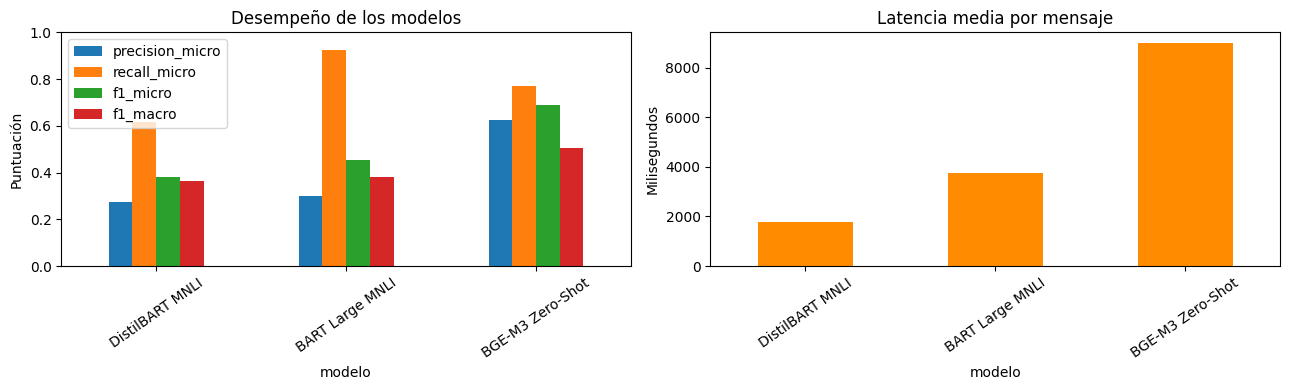

In [23]:
# Visualización de resultados
import matplotlib.pyplot as plt

if not results_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    results_df.plot(
        x="modelo",
        y=["precision_micro", "recall_micro", "f1_micro", "f1_macro"],
        kind="bar",
        ax=axes[0]
    )
    axes[0].set_title("Desempeño de los modelos")
    axes[0].set_ylabel("Puntuación")
    axes[0].set_ylim(0, 1)
    axes[0].tick_params(axis="x", rotation=35)

    results_df.plot(
        x="modelo",
        y="latencia_media_ms",
        kind="bar",
        ax=axes[1],
        legend=False,
        color="darkorange"
    )
    axes[1].set_title("Latencia media por mensaje")
    axes[1].set_ylabel("Milisegundos")
    axes[1].tick_params(axis="x", rotation=35)

    plt.tight_layout()
    plt.show()

In [ ]:
# Probando :D
def predict_message(model_id, text, threshold=0.5):
    classifier = load_classifier(model_id)

    try:
        output = classifier(
            text,
            candidate_labels=CANDIDATE_TEXTS,
            multi_label=True,
            hypothesis_template=HYPOTHESIS_TEMPLATE,
            truncation=True
        )

        score_map = dict(zip(output["labels"], output["scores"]))

        rows = []
        for label, description in CANDIDATE_LABELS.items():
            score = float(score_map[description])
            rows.append({
                "intencion": label,
                "puntuacion": score,
                "detectada": score >= threshold
            })

        return pd.DataFrame(rows).sort_values(
            "puntuacion", ascending=False
        )

    finally:
        del classifier
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


mensaje = (
    "Tengo piel mixta, quiero una crema ligera sin fragancia "
    "y mi presupuesto es de 400 pesos."
)

print(mensaje)

display(
    predict_message(
        MODELS["BGE-M3 Zero-Shot"],
        mensaje
    ).round(3)
)